# Import necessary libraries

In [100]:
import pandas as pd
import numpy as np
from scipy.spatial.distance import cdist
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score

# load data set & check Data info

In [101]:
df = pd.read_csv("data.csv")
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [102]:
df.drop('id', axis=1, inplace=True)
df.drop('Unnamed: 32', axis=1, inplace=True)
df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [103]:
feat=df.drop('diagnosis', axis=1).copy()
feat
df.isnull().values.any()

False

In [104]:
scaler = StandardScaler()
feat = scaler.fit_transform(feat)

# Kmeans function

In [105]:
def kmeans(X, k):
    # Initialize centroids
    random_indices = np.random.choice(len(X), k, replace=False)
    centroids = X[random_indices]

    closest_centroid = np.zeros(len(X)).astype(int)

    max_iters = 100
    for _ in range(max_iters):
        # Assign each data point to the closest centroid
        distances = np.linalg.norm(X[:, np.newaxis, :] - centroids, axis=2)
        closest_centroid = np.argmin(distances, axis=1)
        # Update centroids based on the mean of assigned data points
        for i in range(k):
            centroids[i] = np.mean(X[closest_centroid == i], axis=0)

    return centroids, closest_centroid

# PCA Class

In [106]:
class PCA:
    def __init__(self, n_components):
       self.n_components = n_components
       self.mean = None
       self.explained_variance_ratio_ = None
    def fit(self, X):
       self.mean = np.mean(X, axis=0)
       X = X - self.mean
       cov = np.cov(X.T)
       eigenvalues, eigenvectors = np.linalg.eig(cov)
       idx = np.argsort(eigenvalues)[::-1]
       eigenvalues = eigenvalues[idx]
       eigenvectors = eigenvectors[:, idx]
       self.components = eigenvectors[:, :self.n_components]
       self.explained_variance_ratio_ = eigenvalues[:self.n_components] / np.sum(eigenvalues)
       return self
    def transform(self, X):
       X = X - self.mean
       return np.dot(X, self.components)

# wcss Function

In [107]:
def calculate_wcss(X, centroids, closest_centroids):
    if isinstance(X, np.ndarray):
        wcss = np.sum((X - centroids[closest_centroids])**2)
    else:
        wcss = np.sum((X.to_numpy() - centroids[closest_centroids])**2)
    return wcss


# elbow_Plotting Function

In [108]:
def plot_elbow_method(wcss_values,max_clusters=10):
  plt.plot(range(1,max_clusters+1),wcss_values,marker='o')
  plt.title('Elbow Method')
  plt.xlabel('Number of clusters')
  plt.ylabel('WCSS')
  plt.show()

# Experiment 1

#### Elbow Method

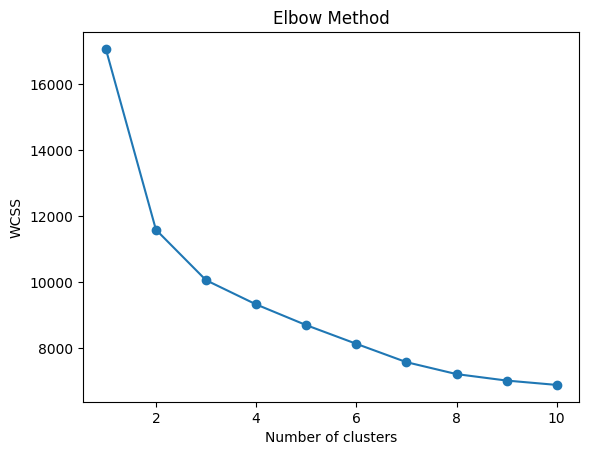

In [109]:
max_clusters=10
wcss_values=[]
for i in range (1,max_clusters+1):
  centroids,closest_centroid=kmeans(feat,i)
  wcss=calculate_wcss(feat,centroids,closest_centroid)
  wcss_values.append(wcss)
plot_elbow_method(wcss_values)

The elbow curve shows a clear bend at k=3, suggesting this is an optimal number of clusters, After k=3, the decrease in WCSS becomes more gradual

#### scatter plot

Experiment 1 :
WCSS: 10065.441178732828
Silhouette Score: 0.3151352252818164


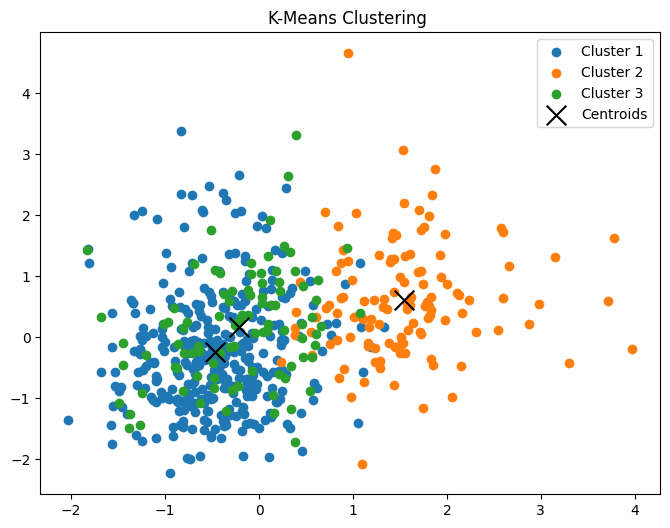

In [110]:
k = 3
centroids, labels = kmeans(feat, k)
wcss_exp1 = calculate_wcss(feat, centroids, labels)
silhouette_exp1 = silhouette_score(feat, labels)
print("Experiment 1 :")
print(f"WCSS: {wcss_exp1}")
print(f"Silhouette Score: {silhouette_exp1}")

plt.figure(figsize=(8, 6))
for i in range(k):
   plt.scatter(feat[labels == i, 0], feat[labels == i, 1], label=f'Cluster {i+1}')
plt.scatter(centroids[:, 0], centroids[:, 1], s=200, c='black', label='Centroids', marker='x')
plt.title('K-Means Clustering ')
plt.legend()
plt.show()

The silhouette score indicates how well-separated the clusters are, A score closer to 1 suggests better-defined clusters 

The clusters show some overlap in the original high-dimensional space, This might indicate that using all 30 features introduces noise

# Experiment 2

#### Explained variance plot

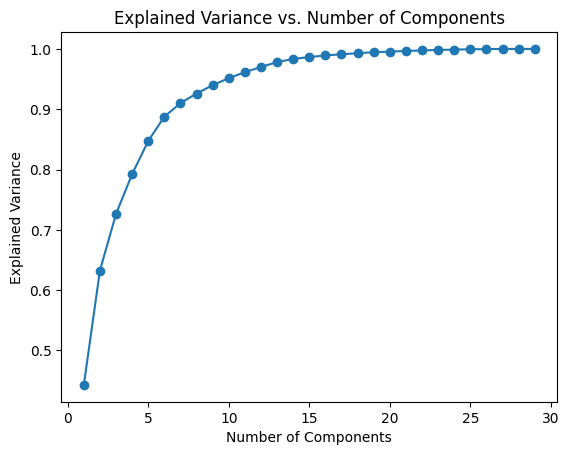

In [111]:
crange = range(1,30)

exp_vars = []
for n_comps in crange:
  pca = PCA(n_comps);
  pca.fit(feat)
  exp_vars.append(np.sum(pca.explained_variance_ratio_))

plt.plot(crange, exp_vars, marker='o')
plt.title('Explained Variance vs. Number of Components')
plt.xlabel('Number of Components')
plt.ylabel('Explained Variance')
plt.show()

We can notice from the figure that about 10 components capture more than 90% of the variance

#### Elbow with different PCA

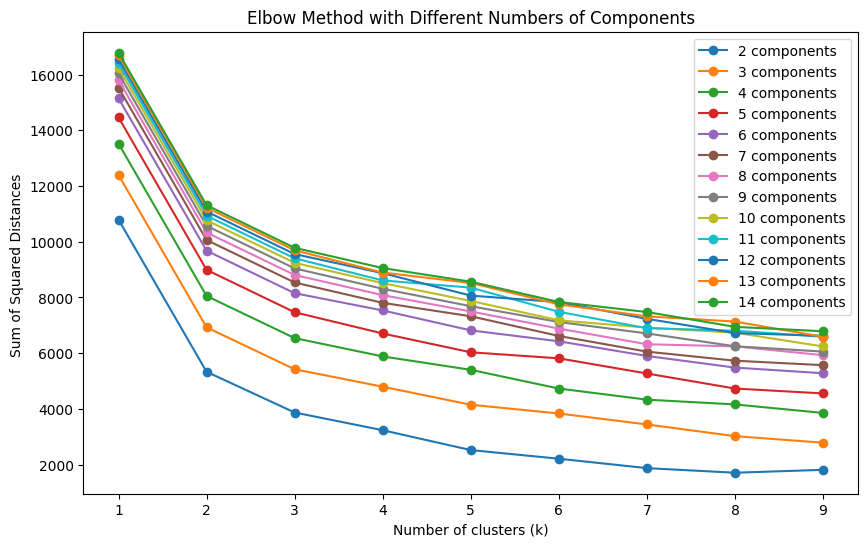

In [112]:
components_range = range(2, 15)
sse_arr = []
for num_components in components_range:
    # Apply PCA to reduce dimensionality
    pca = PCA(n_components = num_components)
    pca.fit(feat)
    X_pca= pca.transform(feat)
    k_values = range(1, 10)
    sse_pca = []
    for k in k_values:
        centroids, labels = kmeans(X_pca, k)
        sum_squared_distances = calculate_wcss(X_pca, centroids, labels)
        sse_pca.append(sum_squared_distances)
    sse_arr.append(sse_pca)
plt.figure(figsize=(10, 6))
for i, sse_pca in enumerate(sse_arr):
    plt.plot(k_values, sse_pca, marker='o', label=f'{components_range[i]} components')

plt.xlabel('Number of clusters (k)')
plt.ylabel('Sum of Squared Distances ')
plt.title('Elbow Method with Different Numbers of Components')
plt.legend()
plt.show()


#### Scatter plots with different PCA

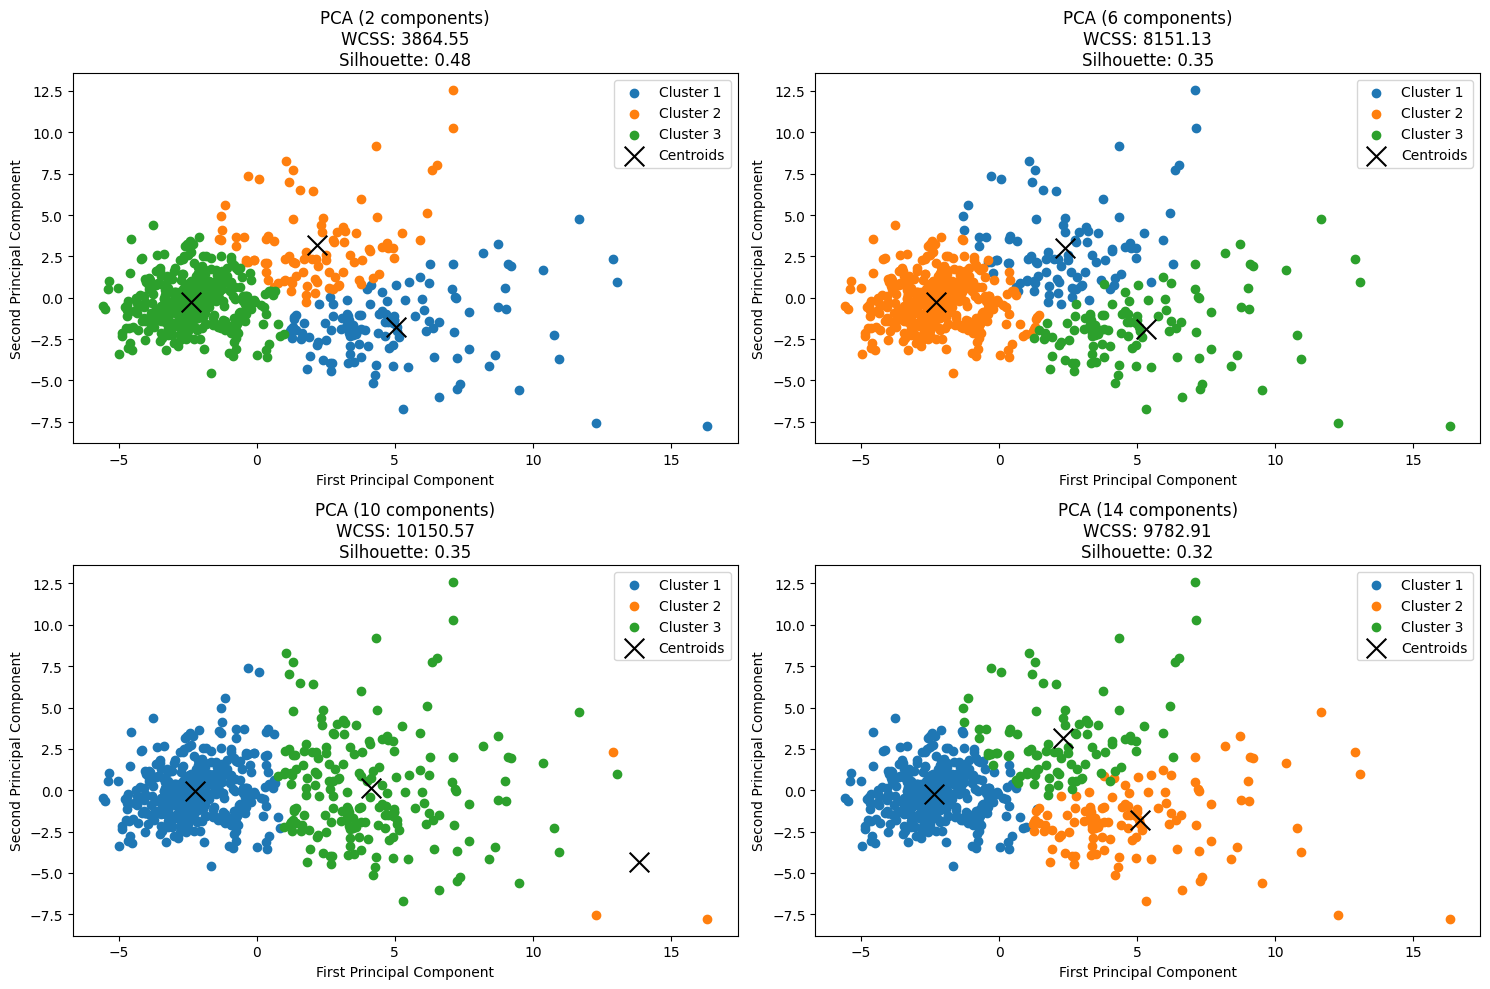

In [113]:
components_range = [2, 6, 10, 14]
k = 3
plt.figure(figsize=(15, 10))
for idx, n_components in enumerate(components_range):
   pca = PCA(n_components=n_components)
   pca.fit(feat)
   X_pca = pca.transform(feat)
   centroids, labels = kmeans(X_pca, k)
   wcss = calculate_wcss(X_pca, centroids, labels)
   silhouette = silhouette_score(X_pca, labels)
   plt.subplot(2, 2, idx + 1)

   for i in range(k):
       plt.scatter(X_pca[labels == i, 0], 
                  X_pca[labels == i, 1], 
                  label=f'Cluster {i+1}')

   plt.scatter(centroids[:, 0], 
              centroids[:, 1], 
              c='black', 
              marker='x', 
              s=200, 
              label='Centroids')

   plt.title(f'PCA ({n_components} components)\nWCSS: {wcss:.2f}\nSilhouette: {silhouette:.2f}')
   plt.xlabel('First Principal Component')
   plt.ylabel('Second Principal Component')
   plt.legend()
plt.tight_layout()
plt.show()

#### stats

In [114]:
k = 3
pca = PCA(n_components=10)
pca.fit(feat)
X_best_pca_optimal = pca.transform(feat)
print("\nPCA Explained Variance Ratio:", pca.explained_variance_ratio_)
print("Total Variance Explained:", sum(pca.explained_variance_ratio_))
best_centroids_optimal, best_labels_optimal = kmeans(X_best_pca_optimal, k)
wcss_exp2 = calculate_wcss(X_best_pca_optimal, best_centroids_optimal, best_labels_optimal)
silhouette_exp2 = silhouette_score(X_best_pca_optimal, best_labels_optimal)
print("\nExperiment 2 Metrics:")
print(f"WCSS: {wcss_exp2}")
print(f"Silhouette Score: {silhouette_exp2}")


PCA Explained Variance Ratio: [0.44272026 0.18971182 0.09393163 0.06602135 0.05495768 0.04024522
 0.02250734 0.01588724 0.01389649 0.01168978]
Total Variance Explained: 0.9515688143366667

Experiment 2 Metrics:
WCSS: 9242.656022273266
Silhouette Score: 0.32724593580626105


Silhouette Score is better and The WCSS is lower because we are working in a reduced dimension

#### Scatter plot

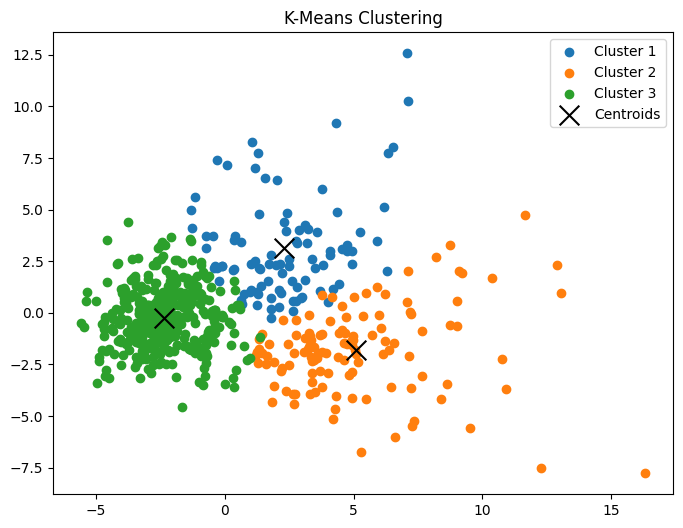

In [115]:
plt.figure(figsize=(8, 6))
for i in range(k):
    plt.scatter(X_best_pca_optimal[best_labels_optimal == i, 0], X_best_pca_optimal[best_labels_optimal == i, 1], label=f'Cluster {i+1}')
# Plot the centroids
plt.scatter(best_centroids_optimal[:, 0], best_centroids_optimal[:, 1], s=200, c='black', label='Centroids', marker='x')
plt.title('K-Means Clustering')
plt.legend()
plt.show()

The clusters show better separation in PCA space

#### Comparison with original labels

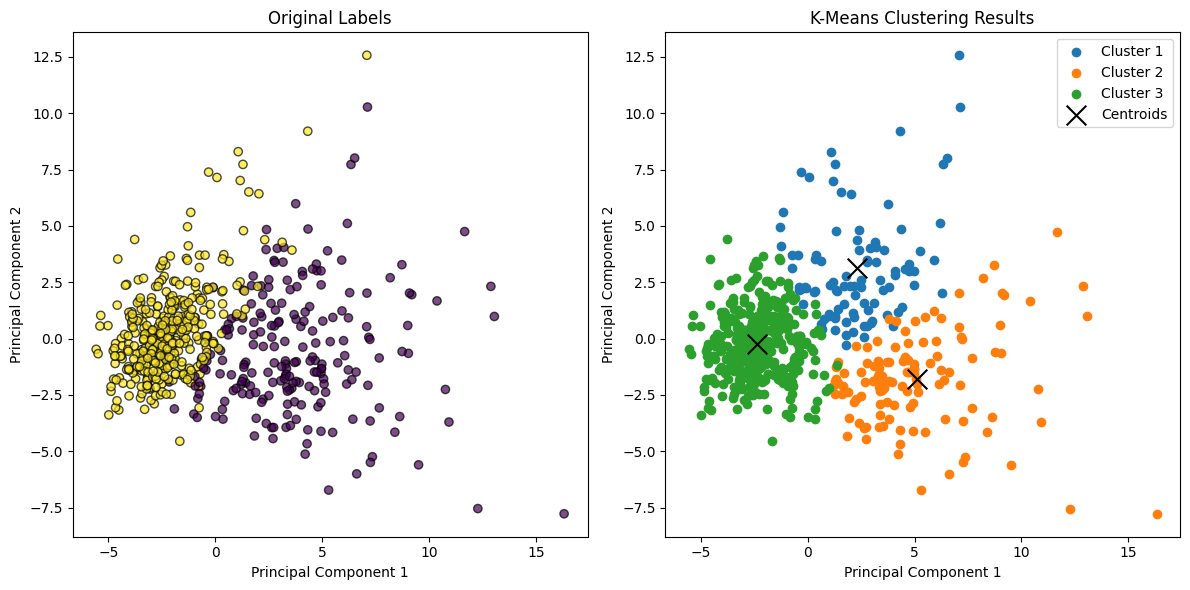

In [116]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.scatter(X_best_pca_optimal[:, 0], X_best_pca_optimal[:, 1], c=df['diagnosis'].map({'M': 0, 'B': 1}), cmap='viridis', edgecolors='k', alpha=0.7)
plt.title('Original Labels')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.subplot(1, 2, 2)
for i in range(k):
    plt.scatter(X_best_pca_optimal[best_labels_optimal == i, 0], X_best_pca_optimal[best_labels_optimal == i, 1],
                label=f'Cluster {i + 1}')
plt.scatter(best_centroids_optimal[:, 0], best_centroids_optimal[:, 1], s=200, c='black', label='Centroids', marker='x')
plt.title('K-Means Clustering Results')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.tight_layout()
plt.show()


The clustering pattern aligns with the original diagnosis labels, PCA helped remove noise and highlight the main patterns in the data

# Final Comparison

In [117]:
print("\nComparison between experiments:")
print(f"\nExperiment 1 (k-means) WCSS: {wcss_exp1}")
print(f"Experiment 2 (PCA + k-means) WCSS: {wcss_exp2}")
print(f"Experiment 1 Silhouette Score: {silhouette_exp1}")
print(f"Experiment 2 Silhouette Score: {silhouette_exp2}")
# Compare with original labels
true_labels = df['diagnosis'].map({'M': 0, 'B': 1})
ari_exp1 = adjusted_rand_score(true_labels, labels)
ari_exp2 = adjusted_rand_score(true_labels, best_labels_optimal)
print("\ncomparison with true labels:")
print("\nAdjusted Rand Index:")
print(f"Experiment 1: {ari_exp1:.3f}")
print(f"Experiment 2: {ari_exp2:.3f}")


Comparison between experiments:

Experiment 1 (k-means) WCSS: 10065.441178732828
Experiment 2 (PCA + k-means) WCSS: 9242.656022273266
Experiment 1 Silhouette Score: 0.3151352252818164
Experiment 2 Silhouette Score: 0.32724593580626105

comparison with true labels:

Adjusted Rand Index:
Experiment 1: 0.541
Experiment 2: 0.541


Experiment 2 (PCA + k-means) produced better-defined clusters, This suggests that dimensionality reduction helped improve clustering quality

# validation using scikit-learn 


#### scikit-learn Import 

In [118]:
from sklearn.decomposition import PCA as SklearnPCA
from sklearn.cluster import KMeans

#### Experiment 1 Validation 

In [119]:
print("Validation of K-means :\n")
# custom 
k = 3
custom_centroids, custom_labels = kmeans(feat, k)
custom_wcss = calculate_wcss(feat, custom_centroids, custom_labels)
custom_silhouette = silhouette_score(feat, custom_labels)

# Scikit-learn
sklearn_kmeans = KMeans(n_clusters=k, random_state=42)
sklearn_labels = sklearn_kmeans.fit_predict(feat)
sklearn_wcss = sklearn_kmeans.inertia_
sklearn_silhouette = silhouette_score(feat, sklearn_labels)
print("Custom Implementation:")
print(f"WCSS: {custom_wcss:.2f}")
print(f"Silhouette Score: {custom_silhouette:.2f}")
print("\nScikit-learn Implementation:")
print(f"WCSS: {sklearn_wcss:.2f}")
print(f"Silhouette Score: {sklearn_silhouette:.2f}")

Validation of K-means :

Custom Implementation:
WCSS: 10066.28
Silhouette Score: 0.32

Scikit-learn Implementation:
WCSS: 10066.28
Silhouette Score: 0.32


#### Experiment 2 Validation

In [120]:
print("\nValidation of PCA + K-means :\n")
# custom 
custom_pca = PCA(n_components=10)
custom_pca.fit(feat)
custom_transformed = custom_pca.transform(feat)
custom_centroids_pca, custom_labels_pca = kmeans(custom_transformed, k)
custom_wcss_pca = calculate_wcss(custom_transformed, custom_centroids_pca, custom_labels_pca)
custom_silhouette_pca = silhouette_score(custom_transformed, custom_labels_pca)

# Scikit-learn 
sklearn_pca = SklearnPCA(n_components=10)
sklearn_transformed = sklearn_pca.fit_transform(feat)
sklearn_kmeans_pca = KMeans(n_clusters=k, random_state=42)
sklearn_labels_pca = sklearn_kmeans_pca.fit_predict(sklearn_transformed)
sklearn_wcss_pca = sklearn_kmeans_pca.inertia_
sklearn_silhouette_pca = silhouette_score(sklearn_transformed, sklearn_labels_pca)
print("Custom Implementation (PCA + K-means):")
print(f"Explained Variance Ratio: {custom_pca.explained_variance_ratio_}")
print(f"WCSS: {custom_wcss_pca:.2f}")
print(f"Silhouette Score: {custom_silhouette_pca:.2f}")
print("\nScikit-learn Implementation (PCA + K-means):")
print(f"Explained Variance Ratio: {sklearn_pca.explained_variance_ratio_}")
print(f"WCSS: {sklearn_wcss_pca:.2f}")
print(f"Silhouette Score: {sklearn_silhouette_pca:.2f}")


Validation of PCA + K-means :

Custom Implementation (PCA + K-means):
Explained Variance Ratio: [0.44272026 0.18971182 0.09393163 0.06602135 0.05495768 0.04024522
 0.02250734 0.01588724 0.01389649 0.01168978]
WCSS: 9242.66
Silhouette Score: 0.33

Scikit-learn Implementation (PCA + K-means):
Explained Variance Ratio: [0.44272026 0.18971182 0.09393163 0.06602135 0.05495768 0.04024522
 0.02250734 0.01588724 0.01389649 0.01168978]
WCSS: 9242.66
Silhouette Score: 0.33


#### Visualize Comparison

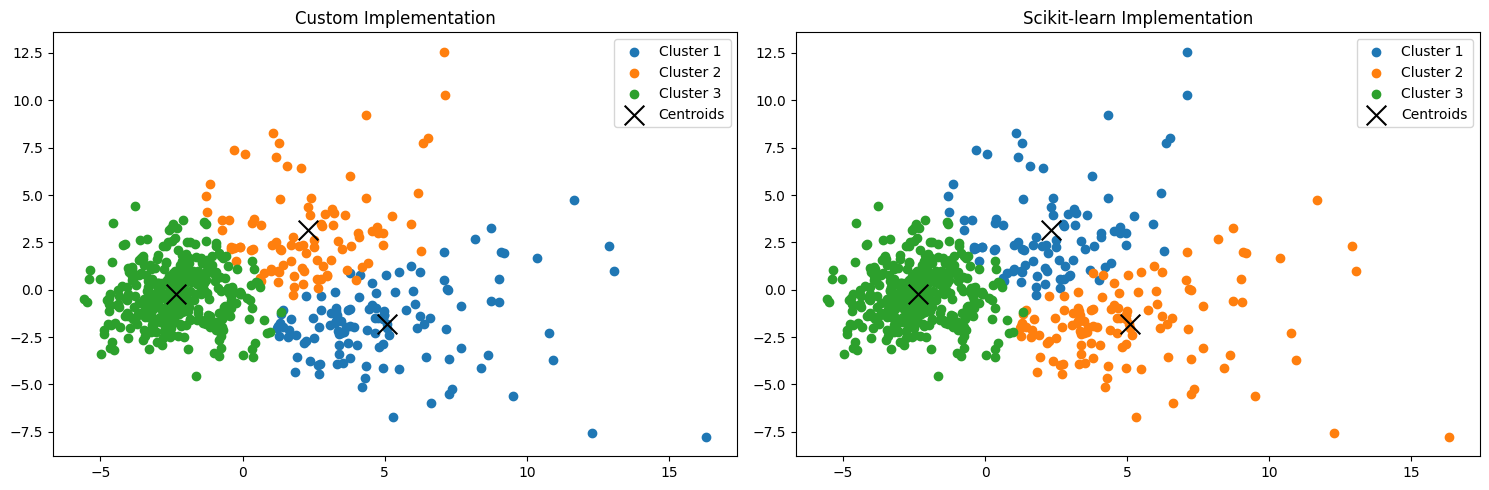

In [121]:
plt.figure(figsize=(15, 5))
# Custom
plt.subplot(1, 2, 1)
for i in range(k):
    plt.scatter(custom_transformed[custom_labels_pca == i, 0], 
               custom_transformed[custom_labels_pca == i, 1], 
               label=f'Cluster {i+1}')
plt.scatter(custom_centroids_pca[:, 0], custom_centroids_pca[:, 1], 
           c='black', marker='x', s=200, label='Centroids')
plt.title('Custom Implementation')
plt.legend()

# Scikit-learn 
plt.subplot(1, 2, 2)
for i in range(k):
    plt.scatter(sklearn_transformed[sklearn_labels_pca == i, 0], 
               sklearn_transformed[sklearn_labels_pca == i, 1], 
               label=f'Cluster {i+1}')
plt.scatter(sklearn_kmeans_pca.cluster_centers_[:, 0], 
           sklearn_kmeans_pca.cluster_centers_[:, 1], 
           c='black', marker='x', s=200, label='Centroids')
plt.title('Scikit-learn Implementation')
plt.legend()
plt.tight_layout()
plt.show()